# League of Legends win predictor (live stats only): audit, cleaning and test-set reserve

**Dataset:** `lol_15min_all.csv`, one row per ranked solo/duo match on NA, captured at the 15:00 mark.
**Target:** `blue_win` (1 = blue side won).

**The constraint:** a prediction made during a real game can only use what the live game API exposes. Per
`lol_snapshots.py`, **gold, XP, tower plates and wards are not available live**, and **CS only updates in steps of 10**.
So this notebook throws away every column the live overlay could not have, and then does the full job on what is left:

1. audits the live-available columns,
2. cleans them and logs every change,
3. **reserves a final test set before any exploration** (the same matches as the full-feature notebook, so the two never leak into each other),
4. documents every column in a data dictionary,
5. makes five interpreted plots (training split only), including one that measures what the restriction costs, and
6. lists the data-quality, sampling and live-versus-training mismatch concerns.

The full-feature version of this work is `lol_15min_audit_and_split.ipynb`. It is left untouched.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e2dd"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2,
})
SEED = 42
DATA_DIR = Path("../data/training")   # run from the notebooks/ folder
ROLES = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]
RANKS = ["IRON", "BRONZE", "SILVER", "GOLD", "PLATINUM", "EMERALD", "DIAMOND", "MASTER_PLUS"]

# What the live API can and cannot give us (from lol_snapshots.py: UNAVAILABLE = gold, xp, plates, wards)
LIVE_STATS = ["level_sum", "cs", "kills", "assists", "towers", "dragons", "heralds", "voidgrubs"]
NOT_LIVE_STATS = ["gold", "xp", "plates", "wards"]

## 1. Load the raw file and drop what the live API cannot provide
`patch` is read as a string on purpose. As a number, patch `16.20` turns into `16.2`.

In [2]:
raw_full = pd.read_csv(DATA_DIR / "lol_15min_all.csv", dtype={"patch": str})

not_live_cols = (
    [f"{side}_{s}" for side in ["blue", "red"] for s in NOT_LIVE_STATS]
    + [f"{s}_diff" for s in NOT_LIVE_STATS]
    + [f"{side}_{r}_gold" for side in ["blue", "red"] for r in ROLES]
    + [f"{r.lower()}_gold_diff" for r in ROLES]
)
assert all(c in raw_full.columns for c in not_live_cols)
raw = raw_full.drop(columns=not_live_cols)

print(f"Loaded {raw_full.shape[0]:,} rows x {raw_full.shape[1]} columns")
print(f"Dropped {len(not_live_cols)} columns the live API cannot provide -> {raw.shape[1]} columns remain")
print("  gold / xp / plates / wards, team totals and differences:", 4 * 3)
print("  per-role gold and per-lane gold differences:", 10 + 5)
raw.drop(columns="player_hashes").head(3).T.head(20)

Loaded 8,167 rows x 70 columns
Dropped 27 columns the live API cannot provide -> 43 columns remain
  gold / xp / plates / wards, team totals and differences: 12
  per-role gold and per-lane gold differences: 15


,0,1,2
match_id,NA1_5647613124,NA1_5660330757,NA1_5645720671
rank_tier,IRON,BRONZE,SILVER
minute,15,15,15
game_start_ms,1790193544575,1792015859448,1789924011743
patch,16.19,16.2,16.18
game_duration_s,1121,1928,1807
blue_win,0,0,0
blue_level_sum,47,47,48
blue_cs,321,359,425
blue_kills,11,8,12


Per-role gold goes too, not only team gold, since it is gold. The champion played in each role stays: the live API does
report each player's champion and position. The current overlay model doesn't use it, but it is available.

## 2. Audit

### 2a. Types, missing values, duplicates, constants

In [3]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "nulls": raw.isna().sum(), "unique": raw.nunique()})
print("Total nulls:", int(raw.isna().sum().sum()))
print("Duplicate match_id:", raw.match_id.duplicated().sum())
print("Fully duplicated rows:", raw.duplicated().sum())
print("Match ids that are not NA1_<digits>:", (~raw.match_id.str.fullmatch(r"NA1_\d+")).sum())
print("Rank values outside the expected list:", (~raw.rank_tier.isin(RANKS)).sum())
print()
print("Constant columns (one unique value):")
display(audit[audit["unique"] == 1])
print("Raw patch values:", raw.patch.value_counts().to_dict())

Total nulls: 0
Duplicate match_id: 0
Fully duplicated rows: 0
Match ids that are not NA1_<digits>: 0
Rank values outside the expected list: 0

Constant columns (one unique value):


,dtype,nulls,unique
minute,int64,0,1
blue_heralds,int64,0,1
red_heralds,int64,0,1
heralds_diff,int64,0,1


Raw patch values: {'16.19': 3914, '16.2': 2662, '16.18': 1591}


No nulls, no duplicates, no malformed ids. `minute`, `blue_heralds`, `red_heralds` and `heralds_diff` are constant:
the Rift Herald has not spawned by 15:00 in this data. The live script does record heralds, but at this snapshot they carry
no information, so they are excluded from modelling. That leaves **8 usable live features** (see section 5).

### 2b. Internal consistency (live columns only)

In [4]:
rows = []
for s in LIVE_STATS:
    rows.append((f"{s}_diff == blue_{s} - red_{s}", int((raw[f"blue_{s}"] - raw[f"red_{s}"] != raw[f"{s}_diff"]).sum())))

ph = raw.player_hashes.str.split(";")
rows.append(("player_hashes has exactly 10 entries", int((ph.str.len() != 10).sum())))
rows.append(("a player appears twice in one match", int((ph.map(lambda l: len(set(l))) < 10).sum())))
rows.append(("same champion on both teams in the same role", int(sum((raw[f"blue_{r}_champ"] == raw[f"red_{r}_champ"]).sum() for r in ROLES))))
rows.append(("a team with a repeated champion", int(sum((raw[[f"{s}_{r}_champ" for r in ROLES]].nunique(axis=1) < 5).sum() for s in ["blue", "red"]))))
rows.append(("blue_first_blood=1 but blue has 0 kills", int(((raw.blue_first_blood == 1) & (raw.blue_kills == 0)).sum())))
rows.append(("blue_first_blood=0 but red has 0 kills", int(((raw.blue_first_blood == 0) & (raw.red_kills == 0)).sum())))
rows.append(("games with zero kills (no first blood possible)", int(((raw.blue_kills + raw.red_kills) == 0).sum())))
display(pd.DataFrame(rows, columns=["check", "violations"]).set_index("check"))

,violations
check,
level_sum_diff == blue_level_sum - red_level_sum,0
cs_diff == blue_cs - red_cs,0
kills_diff == blue_kills - red_kills,0
assists_diff == blue_assists - red_assists,0
towers_diff == blue_towers - red_towers,0
dragons_diff == blue_dragons - red_dragons,0
heralds_diff == blue_heralds - red_heralds,0
voidgrubs_diff == blue_voidgrubs - red_voidgrubs,0
player_hashes has exactly 10 entries,0


Every check passes with zero violations. The `*_diff` columns duplicate the raw totals, so a model should use one or the other.

### 2c. Value ranges and plausibility

In [5]:
num = raw.select_dtypes("number").drop(columns=["minute", "game_start_ms"])
rng_tbl = num.describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]].round(1)
team_cols = [f"blue_{s}" for s in LIVE_STATS if s != "heralds"] + ["game_duration_s"]
diff_cols = [f"{s}_diff" for s in LIVE_STATS if s != "heralds"]
display(rng_tbl.loc[team_cols + diff_cols])

lvl = pd.concat([raw.blue_level_sum, raw.red_level_sum]) / 5
print(f"Average champion level per team: min {lvl.min():.1f}, median {lvl.median():.1f}, max {lvl.max():.1f}")
print(f"Largest team kill count at 15:00: {max(raw.blue_kills.max(), raw.red_kills.max())}")

,min,1%,50%,99%,max
blue_level_sum,37.0,43.0,48.0,53.0,55.0
blue_cs,224.0,301.0,438.0,547.0,587.0
blue_kills,0.0,3.0,12.0,25.0,37.0
blue_assists,0.0,1.0,11.0,28.0,43.0
blue_towers,0.0,0.0,0.0,3.0,6.0
blue_dragons,0.0,0.0,1.0,2.0,2.0
blue_voidgrubs,0.0,0.0,2.0,3.0,3.0
game_duration_s,845.0,916.0,1762.0,2850.0,3706.0
level_sum_diff,-12.0,-7.0,0.0,7.0,12.0
cs_diff,-221.0,-136.0,0.0,135.3,213.0


Average champion level per team: min 7.2, median 9.6, max 11.0
Largest team kill count at 15:00: 37


All ranges are plausible for 15 minutes of play: no negatives and no impossible levels. The extremes (37 kills, a 12-level
gap) are real stomps, so they are kept.

### 2d. Timestamps, patch and game length

In [6]:
raw["start_time"] = pd.to_datetime(raw.game_start_ms, unit="ms")
display(raw.groupby("patch").start_time.agg(["min", "max", "size"]))
print("Collection window:", raw.start_time.min().date(), "to", raw.start_time.max().date())

short = raw[raw.game_duration_s < 900]
print(f"\nGames shorter than 15:00 that still have a '15:00' snapshot: {len(short)}")
display(short[["match_id", "game_duration_s", "blue_win", "level_sum_diff", "kills_diff", "blue_kills", "red_kills"]])
print(f"Games ending between 15:00 and 16:00: {((raw.game_duration_s >= 900) & (raw.game_duration_s < 960)).sum()}")

,min,max,size
patch,,,
16.18,2026-09-14 22:42:20.540,2026-09-23 08:01:59.777,1591
16.19,2026-09-23 14:17:16.418,2026-10-07 08:31:33.495,3914
16.2,2026-10-07 12:28:52.188,2026-10-16 14:22:16.622,2662


Collection window: 2026-09-14 to 2026-10-16

Games shorter than 15:00 that still have a '15:00' snapshot: 8


,match_id,game_duration_s,blue_win,level_sum_diff,kills_diff,blue_kills,red_kills
1412,NA1_5660114828,879,1,5,0,13,13
1985,NA1_5649785243,856,0,-9,-7,2,9
3566,NA1_5652582175,848,0,-6,-9,7,16
4074,NA1_5655301093,859,0,1,0,5,5
4777,NA1_5643096280,845,0,-2,1,8,7
5937,NA1_5660531298,878,1,7,11,14,3
6167,NA1_5649371326,876,0,-5,-8,6,14
7829,NA1_5652024823,897,0,-8,-16,5,21


Games ending between 15:00 and 16:00: 305


**Finding:** 8 matches ended before 15:00, yet carry a 15:00 snapshot, so the row is the final frame, not the state at 15:00. They are
removed in the next section. The games ending in the minutes right after 15:00 are early surrenders (surrender opens at 15:00); those are
real outcomes and stay (see Plot 2).

## 3. Clean

In [7]:
clean_log = []
df = raw.copy()

def step(name, mask_drop=None, note=""):
    global df
    before = len(df)
    if mask_drop is not None:
        df = df[~mask_drop(df)]
    clean_log.append((name, before - len(df), len(df), note))

# 1. Patch strings: '16.2' is patch 16.20
df["patch"] = df.patch.where(df.patch.str.split(".").str[1].str.len() == 2, df.patch + "0")
step("Normalise patch to two-digit minor version", note="16.2 -> 16.20")

# 2. Rows whose '15:00' snapshot is not a real 15:00 state
step("Drop games that ended before 15:00", lambda d: d.game_duration_s < 900,
     "snapshot is the last frame, not the 15:00 state")

# 3. Order rows by time
df = df.sort_values("game_start_ms").reset_index(drop=True)
step("Sort by game start time")

# 4. Types
df["rank_tier"] = pd.Categorical(df.rank_tier, categories=RANKS, ordered=True)
df["blue_win"] = df.blue_win.astype("int8")
df["blue_first_blood"] = df.blue_first_blood.astype("int8")
step("Cast rank_tier to ordered category, flags to int8")

# 5. Derived columns
df["game_minutes"] = df.game_duration_s / 60
df["n_champs_unique"] = df[[f"{s}_{r}_champ" for s in ["blue", "red"] for r in ROLES]].nunique(axis=1)

# Live CS only updates in steps of 10, so a live reading is up to 9 below the true count for each player.
# The data holds team totals only, so mimic it by removing 0-9 CS per player (5 players a side), fixed seed.
cs_rng = np.random.default_rng(SEED + 1)
lost_blue = cs_rng.integers(0, 10, (len(df), 5)).sum(axis=1)
lost_red = cs_rng.integers(0, 10, (len(df), 5)).sum(axis=1)
df["cs_diff_live_sim"] = df.cs_diff - lost_blue + lost_red
step("Add game_minutes, n_champs_unique, cs_diff_live_sim", note="cs_diff_live_sim is a simulation, see section 5")

display(pd.DataFrame(clean_log, columns=["step", "rows_removed", "rows_after", "note"]))
print(f"\nRaw {len(raw):,} -> clean {len(df):,} rows ({len(raw) - len(df)} removed, {(len(raw) - len(df)) / len(raw):.2%})")
print("Patches:", sorted(df.patch.unique(), key=lambda p: tuple(map(int, p.split(".")))))

,step,rows_removed,rows_after,note
0,Normalise patch to two-digit minor version,0,8167,16.2 -> 16.20
1,Drop games that ended before 15:00,8,8159,"snapshot is the last frame, not the 15:00 state"
2,Sort by game start time,0,8159,
3,"Cast rank_tier to ordered category, flags to int8",0,8159,
4,"Add game_minutes, n_champs_unique, cs_diff_liv...",0,8159,"cs_diff_live_sim is a simulation, see section 5"



Raw 8,167 -> clean 8,159 rows (8 removed, 0.10%)
Patches: ['16.18', '16.19', '16.20']


What was **not** done, and why:

* **No outlier removal.** Big leads are real games and are where the model has to be confident.
* **No imputation.** Nothing is missing.
* **Exact CS is kept** next to the simulated live CS, so a model can train on exact CS and be evaluated on live-style CS, the way `lol_eda_10_vs_15.ipynb` does.

## 4. Reserve the final test set
The test set is carved out **now**, before plotting or feature choices.

* 20% of matches, stratified by `rank_tier` x `blue_win`, seed `42`, exactly the procedure used in `lol_15min_audit_and_split.ipynb`.
* Because the cleaning steps and seed are identical, the held-out matches should be **the same ones** as in the full-feature notebook. That is checked
  below against the saved fingerprint. If the two notebooks used different test sets, a match could be held out in one and used for training in the other, which would
  quietly leak. The split must not change when the feature set does.

In [8]:
TEST_FRAC = 0.20
strata = df.rank_tier.astype(str) + "_" + df.blue_win.astype(str)

rng = np.random.default_rng(SEED)
test_idx = []
for _, idx in df.groupby(strata, observed=True).groups.items():
    idx = np.array(idx)
    n_test = int(round(len(idx) * TEST_FRAC))
    test_idx.extend(rng.choice(idx, size=n_test, replace=False))

is_test = df.index.isin(test_idx)
train, test = df[~is_test].copy(), df[is_test].copy()

assert set(train.match_id).isdisjoint(test.match_id), "train and test overlap"
assert len(train) + len(test) == len(df)
print(f"train: {len(train):,} matches   test (reserved): {len(test):,} matches ({len(test) / len(df):.1%})")

fingerprint = hashlib.sha256("\n".join(sorted(test.match_id)).encode()).hexdigest()
existing = DATA_DIR / "lol_15min_test_HOLDOUT.sha256"
if existing.exists():
    same = existing.read_text().strip() == fingerprint
    print("Same held-out matches as the full-feature notebook:", same)
    assert same, "holdout differs from the full-feature notebook; do not overwrite either"
else:
    existing.write_text(fingerprint + "\n")
    print("No earlier fingerprint found; wrote a new one.")

display(pd.DataFrame({"train": [train.blue_win.mean()], "test": [test.blue_win.mean()]}, index=["blue win rate"]).round(4))
display(pd.concat({"train": train.rank_tier.value_counts(normalize=True),
                   "test": test.rank_tier.value_counts(normalize=True)}, axis=1).reindex(RANKS).round(3))
display(pd.concat({"train": train.patch.value_counts(normalize=True),
                   "test": test.patch.value_counts(normalize=True)}, axis=1).round(3))

train: 6,527 matches   test (reserved): 1,632 matches (20.0%)
Same held-out matches as the full-feature notebook: True


,train,test
blue win rate,0.4923,0.4914


,train,test
rank_tier,,
IRON,0.125,0.125
BRONZE,0.124,0.124
SILVER,0.126,0.125
GOLD,0.125,0.125
PLATINUM,0.125,0.126
EMERALD,0.125,0.126
DIAMOND,0.125,0.125
MASTER_PLUS,0.125,0.125


,train,test
patch,,
16.19,0.484,0.460
16.20,0.325,0.331
16.18,0.191,0.209


In [9]:
chi_p = stats.chi2_contingency(pd.crosstab(is_test, df.patch))[1]
print(f"patch mix train vs test: chi-square p = {chi_p:.2f} (large p = no evidence of imbalance)")
for f in ["level_sum_diff", "kills_diff", "cs_diff"]:
    print(f"{f} train vs test: KS p = {stats.ks_2samp(train[f], test[f]).pvalue:.2f}")

# Live-only files: same matches as the full-feature split, without any column the live API cannot provide.
train.to_csv(DATA_DIR / "lol_15min_live_train.csv", index=False)
test.to_csv(DATA_DIR / "lol_15min_live_test_HOLDOUT.csv", index=False)
print("Saved lol_15min_live_train.csv and lol_15min_live_test_HOLDOUT.csv")

patch mix train vs test: chi-square p = 0.15 (large p = no evidence of imbalance)
level_sum_diff train vs test: KS p = 0.40
kills_diff train vs test: KS p = 0.46
cs_diff train vs test: KS p = 0.10
Saved lol_15min_live_train.csv and lol_15min_live_test_HOLDOUT.csv


From here on, **only `train` is used**, apart from one comparison in Plot 5 that pulls the non-live columns back in for training rows only,
to measure what the restriction costs. Select models with cross-validation inside `train`; touch the holdout once.

## 5. Data dictionary
`live?` says whether the live game API can supply it when predicting during a game. Only live columns can feed the overlay model;
the others are kept for audit and for building the training set.

In [10]:
D = []
def add(col, desc, dtype, unit, live, model, notes=""):
    D.append((col, desc, dtype, unit, live, model, notes))

add("match_id", "Riot match identifier (NA1_<number>)", "string", "id", "n/a", "no", "unique key")
add("rank_tier", "Rank bracket the match was sampled from", "ordered category", "8 levels", "n/a", "optional", "sampled ~equal per rank, so not the natural rank mix; unknown in a live game")
add("minute", "Snapshot time", "int", "minutes", "n/a", "no", "constant = 15")
add("game_start_ms", "Game start", "int", "Unix epoch ms", "n/a", "no", "")
add("patch", "Game version", "string", "major.minor", "n/a", "optional", "16.18, 16.19, 16.20; kept as text")
add("game_duration_s", "Total length of the game", "int", "seconds", "NO", "NO", "LEAKS: only known after the game; auditing only")
add("game_minutes", "game_duration_s / 60 (added)", "float", "minutes", "NO", "NO", "leaks, as above")
add("player_hashes", "Anonymised ids of the 10 players, ';' separated", "string", "id", "NO", "no", "used only to measure repeat players")
add("blue_win", "TARGET: 1 if blue side won", "int8", "0/1", "n/a", "target", "~49% positive")
add("n_champs_unique", "Distinct champions in the match (added)", "int", "count", "n/a", "no", "always 10; consistency check")
unit = {"level_sum": "levels", "cs": "count", "kills": "count", "assists": "count", "towers": "count",
        "dragons": "count", "heralds": "count", "voidgrubs": "count"}
desc = {"level_sum": "sum of the 5 champion levels", "cs": "minions and monsters killed", "kills": "champion kills",
        "assists": "kill assists", "towers": "towers destroyed", "dragons": "dragons taken",
        "heralds": "Rift Heralds taken", "voidgrubs": "Void Grubs taken"}
extra = {"cs": "live API updates in steps of 10 per player", "heralds": "constant 0 at 15:00",
         "dragons": "0-2 in this data", "voidgrubs": "0-3"}
for side in ["blue", "red"]:
    for s in LIVE_STATS:
        add(f"{side}_{s}", f"{side.title()} {desc[s]}", "int", unit[s], "yes", "via " + s + "_diff", extra.get(s, ""))
    for r in ROLES:
        add(f"{side}_{r}_champ", f"Champion played by {side} {r.lower()}", "string", "~170 values", "yes", "optional", "available live; not used by the current overlay model")
add("blue_first_blood", "1 if blue got the first kill", "int8", "0/1", "yes", "yes", "")
for s in LIVE_STATS:
    add(f"{s}_diff", f"Blue minus red {desc[s]}", "int", "blue - red", "yes", "no" if s == "heralds" else "yes",
        "positive = blue ahead" + ("; constant 0" if s == "heralds" else "; live value is rounded down to 10s per player, see cs_diff_live_sim" if s == "cs" else ""))
add("cs_diff_live_sim", "cs_diff with 0-9 CS removed per player (added)", "int", "blue - red", "simulated", "evaluation only",
    "approximates the live API's step-of-10 CS; use to test, train on exact cs_diff")

dictionary = pd.DataFrame(D, columns=["column", "description", "dtype", "unit", "live?", "model_input", "notes"])
cols_in_data = set(train.columns) - {"start_time"}
print("Columns in data but not documented:", sorted(cols_in_data - set(dictionary.column)) or "none")
print("Documented but not in data:", sorted(set(dictionary.column) - cols_in_data) or "none")
dictionary.to_csv(DATA_DIR / "lol_15min_live_data_dictionary.csv", index=False)
with pd.option_context("display.max_colwidth", 80):
    display(dictionary)

Columns in data but not documented: none
Documented but not in data: none


,column,description,dtype,unit,live?,model_input,notes
0,match_id,Riot match identifier (NA1_<number>),string,id,n/a,no,unique key
1,rank_tier,Rank bracket the match was sampled from,ordered category,8 levels,n/a,optional,"sampled ~equal per rank, so not the natural rank mix; unknown in a live game"
2,minute,Snapshot time,int,minutes,n/a,no,constant = 15
3,game_start_ms,Game start,int,Unix epoch ms,n/a,no,
4,patch,Game version,string,major.minor,n/a,optional,"16.18, 16.19, 16.20; kept as text"
5,game_duration_s,Total length of the game,int,seconds,NO,NO,LEAKS: only known after the game; auditing only
6,game_minutes,game_duration_s / 60 (added),float,minutes,NO,NO,"leaks, as above"
7,player_hashes,"Anonymised ids of the 10 players, ';' separated",string,id,NO,no,used only to measure repeat players
8,blue_win,TARGET: 1 if blue side won,int8,0/1,n/a,target,~49% positive
9,n_champs_unique,Distinct champions in the match (added),int,count,n/a,no,always 10; consistency check


The columns removed in section 1 (gold, XP, plates, wards and per-role gold) are deliberately **not** in this dictionary: they are
not live, so they are not part of this dataset.

In [11]:
LIVE_FEATURES = ["level_sum_diff", "cs_diff", "kills_diff", "assists_diff", "towers_diff",
                 "dragons_diff", "voidgrubs_diff", "blue_first_blood"]   # heralds dropped: constant at 15:00
print(f"{len(LIVE_FEATURES)} live predictors:", LIVE_FEATURES)

8 live predictors: ['level_sum_diff', 'cs_diff', 'kills_diff', 'assists_diff', 'towers_diff', 'dragons_diff', 'voidgrubs_diff', 'blue_first_blood']


## 6. Plots (training data only)

### Plot 1. Class balance and win rate by rank

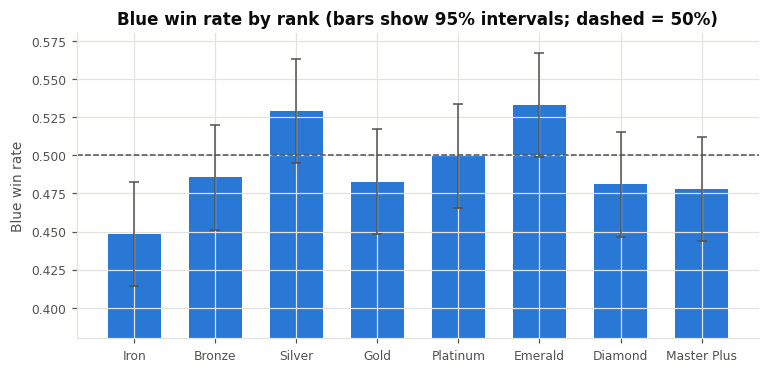

Overall blue win rate: 0.492  (3,213 of 6,527)
Is the win rate the same across ranks? chi-square p = 0.0127
Binomial test of overall rate vs 50%: p = 0.216


In [12]:
g = train.groupby("rank_tier", observed=True).blue_win.agg(["mean", "size"]).reindex(RANKS)
se = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
overall = train.blue_win.mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(g)), g["mean"], yerr=1.96 * se, color=BLUE, width=0.65, error_kw=dict(ecolor=INK2, capsize=3, lw=1))
ax.axhline(0.5, color=INK2, ls="--", lw=1)
ax.set_xticks(range(len(g)), [r.replace("_", " ").title() for r in RANKS])
ax.set(ylim=(0.38, 0.58), ylabel="Blue win rate",
       title="Blue win rate by rank (bars show 95% intervals; dashed = 50%)")
plt.show()

chi_p = stats.chi2_contingency(pd.crosstab(train.rank_tier, train.blue_win))[1]
print(f"Overall blue win rate: {overall:.3f}  ({train.blue_win.sum():,} of {len(train):,})")
print(f"Is the win rate the same across ranks? chi-square p = {chi_p:.4f}")
print(f"Binomial test of overall rate vs 50%: p = {stats.binomtest(int(train.blue_win.sum()), len(train)).pvalue:.3f}")

**Reading it.** The classes are balanced: blue wins 49.2% of games, which is not distinguishable from 50% (p = 0.22), so accuracy is a fair metric next to AUC and no side
adjustment is needed. This plot doesn't depend on which features are live, so it matches the full-feature notebook.

The ranks are *not* all the same (chi-square p = 0.013). Iron is the low outlier (44.9%), and Silver (52.9%) and Emerald (53.3%) are high. There is no trend up or down the ladder, so this isn't a clean
"blue is stronger at higher ranks" effect, and with eight groups and one test it is suggestive rather than settled. Rank is unknown during a live game, so it can't be a model input; it is useful
for reporting holdout results per rank.

### Plot 2. How long games last: the survivorship filter

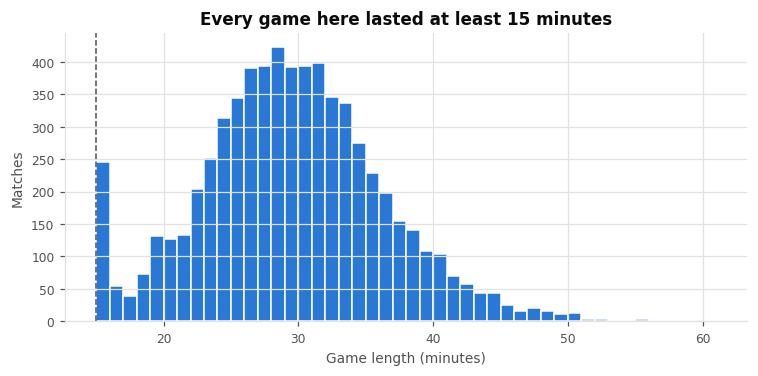

Median game: 29.4 min; 90% of games end by 38 min
Games over by 16:00 (early surrenders): 3.8%
Games over by 18:00: 5.2%

Level gap >= 4 at 15:00: 25.9% of games; 15.2% of them end before 18:00
Level gap < 4:           74.1% of games; 1.7% of them end before 18:00


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(train.game_minutes, bins=np.arange(15, 62, 1), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(15, color=INK2, ls="--", lw=1)
ax.set(xlabel="Game length (minutes)", ylabel="Matches", title="Every game here lasted at least 15 minutes")
plt.show()

print(f"Median game: {train.game_minutes.median():.1f} min; 90% of games end by {train.game_minutes.quantile(.9):.0f} min")
print(f"Games over by 16:00 (early surrenders): {(train.game_minutes < 16).mean():.1%}")
print(f"Games over by 18:00: {(train.game_minutes < 18).mean():.1%}")

big = train.level_sum_diff.abs() >= 4
print(f"\nLevel gap >= 4 at 15:00: {big.mean():.1%} of games; {(train[big].game_minutes < 18).mean():.1%} of them end before 18:00")
print(f"Level gap < 4:           {(~big).mean():.1%} of games; {(train[~big].game_minutes < 18).mean():.1%} of them end before 18:00")

**Reading it.** The histogram starts at 15 minutes because only games still running at 15:00 are in the data. The spike right after 15:00, when surrender unlocks, holds 3.8% of games ending before 16:00.
Those games are lopsided. Without gold, the level gap is the best live way to see it: when one team is 4+ levels ahead (26% of games), 15% are over before 18:00, compared with 1.7% of games with a smaller gap.
They are real outcomes, so they stay in, but they make 15:00 easier to predict than the average moment in a game. Accuracy here applies to "games that reach 15:00".

### Plot 3. The two strongest live signals against win rate

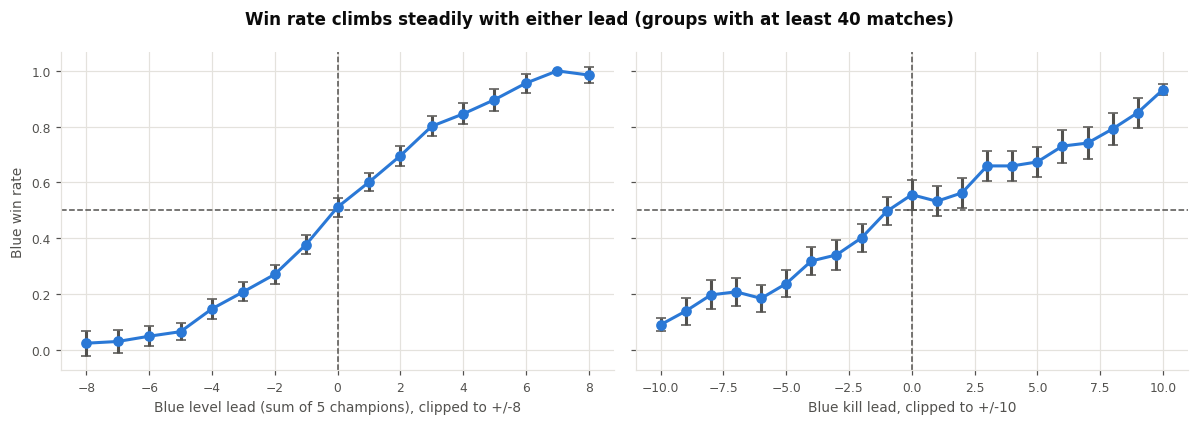

level_sum_diff


level_sum_diff,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
mean,0.023,0.029,0.048,0.065,0.146,0.208,0.270,0.377,0.511,0.601,0.695,0.801,0.846,0.897,0.956,1.0,0.985
size,43.000,68.000,145.000,232.000,355.000,554.000,659.000,790.000,859.000,839.000,660.000,473.000,356.000,232.000,136.000,59.0,67.000
se,0.023,0.020,0.018,0.016,0.019,0.017,0.017,0.017,0.017,0.017,0.018,0.018,0.019,0.020,0.018,0.0,0.015


kills_diff


kills_diff,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
mean,0.090,0.138,0.196,0.207,0.184,0.237,0.318,0.340,0.401,0.496,0.556,0.532,0.562,0.659,0.659,0.673,0.73,0.741,0.792,0.850,0.932
size,580.000,195.000,224.000,241.000,250.000,287.000,352.000,303.000,359.000,377.000,331.000,325.000,336.000,311.000,308.000,294.000,215.00,224.000,197.000,167.000,651.000
se,0.012,0.025,0.027,0.026,0.025,0.025,0.025,0.027,0.026,0.026,0.027,0.028,0.027,0.027,0.027,0.027,0.03,0.029,0.029,0.028,0.010


In [14]:
def curve(feature, lo, hi, min_n=40):
    x = train[feature].clip(lo, hi)
    g = train.groupby(x).blue_win.agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    g["se"] = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    return g

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
panels = [("level_sum_diff", -8, 8, "Blue level lead (sum of 5 champions), clipped to +/-8"),
          ("kills_diff", -10, 10, "Blue kill lead, clipped to +/-10")]
tables = {}
for ax, (f, lo, hi, label) in zip(axes, panels):
    c = curve(f, lo, hi)
    tables[f] = c
    ax.errorbar(c.index, c["mean"], yerr=1.96 * c.se, fmt="o-", color=BLUE, ecolor=INK2, capsize=3)
    ax.axhline(0.5, color=INK2, ls="--", lw=1); ax.axvline(0, color=INK2, ls="--", lw=1)
    ax.set(xlabel=label)
axes[0].set_ylabel("Blue win rate")
fig.suptitle("Win rate climbs steadily with either lead (groups with at least 40 matches)", fontweight="bold", color=INK, fontsize=11)
fig.tight_layout()
plt.show()
for f, c in tables.items():
    print(f); display(c.round(3).T)

**Reading it.** With gold gone, level and kills are the two strongest live signals. Level is the sharper one: from an even level sum (51% win rate) each extra level of lead adds about 10 points,
so +2 levels is roughly 70% and +4 is about 85%. Behind by 4 levels is about 15%. Kills climb more slowly, at about 4 to 5 points per kill. The end points are clipped (the 580 games 10 or more kills behind win
9%, the 651 games 10 or more ahead win 93%), so those two points are groups, not single values. Kills at 0 or +1 sit above 50% only by noise (the intervals cover 50%).
These are the same S-shaped relationships a logistic regression expects. Neither alone is a guarantee: even a team 3 levels ahead loses about one game in five.

### Plot 4. Which live features carry signal, and how redundant they are

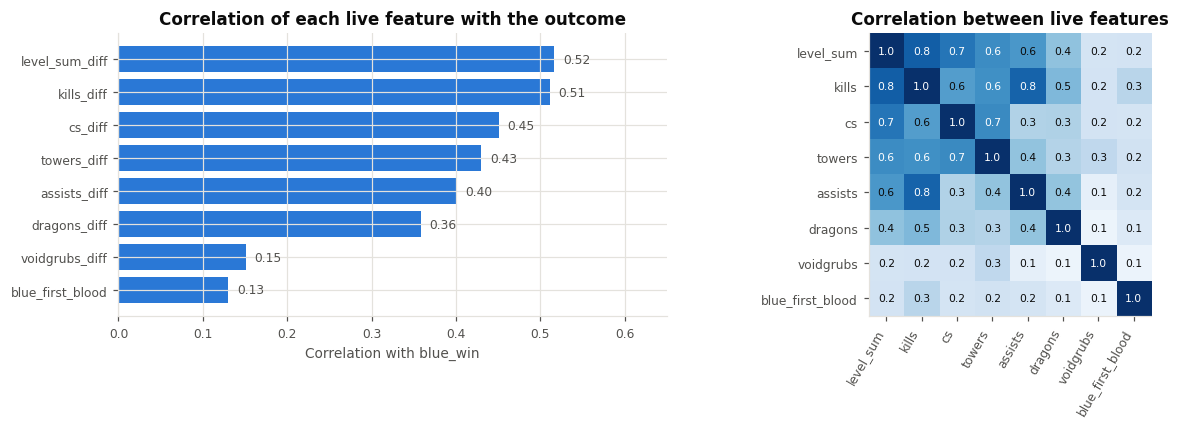

Correlation with win: {'level_sum_diff': 0.52, 'kills_diff': 0.51, 'cs_diff': 0.45, 'towers_diff': 0.43, 'assists_diff': 0.4, 'dragons_diff': 0.36, 'voidgrubs_diff': 0.15, 'blue_first_blood': 0.13}
level vs kills: 0.82 | level vs cs: 0.73 | kills vs assists: 0.8
cs_diff with win: exact 0.451 | live-rounded 0.445


In [15]:
corr_t = train[LIVE_FEATURES + ["blue_win"]].corr()
signal = corr_t["blue_win"].drop("blue_win").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), gridspec_kw={"width_ratios": [1, 1.05]})
axes[0].barh(signal.index, signal.values, color=BLUE)
axes[0].set(xlabel="Correlation with blue_win", title="Correlation of each live feature with the outcome")
for y, v in enumerate(signal.values):
    axes[0].text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color=INK2)
axes[0].set_xlim(0, 0.65)

order = ["level_sum_diff", "kills_diff", "cs_diff", "towers_diff", "assists_diff", "dragons_diff", "voidgrubs_diff", "blue_first_blood"]
cm = train[order].corr()
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(order)), [o.replace("_diff", "") for o in order], rotation=60, ha="right")
axes[1].set_yticks(range(len(order)), [o.replace("_diff", "") for o in order])
axes[1].grid(False)
for i in range(len(order)):
    for j in range(len(order)):
        axes[1].text(j, i, f"{cm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7,
                     color="white" if cm.iloc[i, j] > 0.6 else INK)
axes[1].set_title("Correlation between live features")
fig.tight_layout()
plt.show()

print("Correlation with win:", signal.sort_values(ascending=False).round(2).to_dict())
print("level vs kills:", round(cm.loc["level_sum_diff", "kills_diff"], 2), "| level vs cs:", round(cm.loc["level_sum_diff", "cs_diff"], 2),
      "| kills vs assists:", round(cm.loc["kills_diff", "assists_diff"], 2))
print("cs_diff with win: exact", round(train.cs_diff.corr(train.blue_win), 3), "| live-rounded", round(train.cs_diff_live_sim.corr(train.blue_win), 3))

**Reading it.** Level (0.52) and kills (0.51) track the outcome most, followed by CS (0.45), towers (0.43) and assists (0.40). Dragons (0.36) are moderate; void grubs (0.15) and first blood (about 0.13)
are weak on their own. These features overlap (level vs kills 0.82, kills vs assists 0.80, level vs CS 0.73), so adding them all improves a model less than their individual correlations suggest. The overlap
is smaller than in the full-feature set, where gold and XP were 0.9 correlated with almost everything. Live-style CS rounding barely changes CS's signal: 0.451 exact against 0.445 rounded.
Dragons, grubs and first blood overlap least with the rest, so they are the likeliest to add something.

### Plot 5. What does restricting to live stats cost?

This is the one place the non-live columns are used, and only for **training rows**, via `match_id`, to measure the loss. Each bar is
5-fold cross-validated AUC of a plain logistic regression inside `train`. The third bar trains on exact CS but is scored on step-of-10 CS,
like the real overlay. The holdout is not involved.

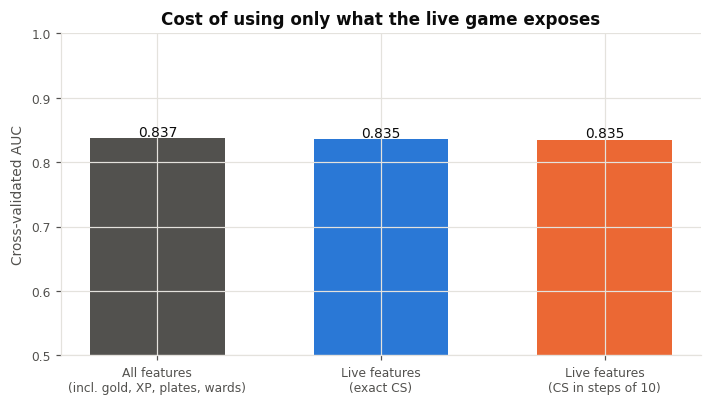

,auc_mean,auc_sd_across_seeds
"All features\n(incl. gold, XP, plates, wards)",0.8373,0.0003
Live features\n(exact CS),0.8354,0.0001
Live features\n(CS in steps of 10),0.8349,0.0001


AUC lost going from all features to live features (exact CS): 0.0019
AUC lost to step-of-10 CS rounding: 0.0005


In [16]:
nl = raw_full.set_index("match_id").loc[train.match_id, [f"{s}_diff" for s in NOT_LIVE_STATS]].reset_index(drop=True)
Xall = pd.concat([train.reset_index(drop=True), nl], axis=1)
y = Xall.blue_win.to_numpy()
FULL_FEATURES = LIVE_FEATURES + [f"{s}_diff" for s in NOT_LIVE_STATS]

def cv_auc(features, score_cs_col=None, seeds=(0, 1, 2)):
    aucs = []
    for sd in seeds:
        oof = np.zeros(len(Xall))
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=sd).split(Xall, y):
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)).fit(Xall.loc[tr, features], y[tr])
            Xv = Xall.loc[va, features].copy()
            if score_cs_col:
                Xv["cs_diff"] = Xall.loc[va, score_cs_col]
            oof[va] = m.predict_proba(Xv)[:, 1]
        aucs.append(roc_auc_score(y, oof))
    return float(np.mean(aucs)), float(np.std(aucs))

res = {
    "All features\n(incl. gold, XP, plates, wards)": cv_auc(FULL_FEATURES),
    "Live features\n(exact CS)": cv_auc(LIVE_FEATURES),
    "Live features\n(CS in steps of 10)": cv_auc(LIVE_FEATURES, score_cs_col="cs_diff_live_sim"),
}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
names = list(res)
vals = [res[k][0] for k in names]
ax.bar(range(3), vals, color=[INK2, BLUE, ORANGE], width=0.6)
for i, v in enumerate(vals):
    ax.text(i, v + 0.003, f"{v:.3f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(3), names)
ax.set(ylim=(0.5, 1.0), ylabel="Cross-validated AUC", title="Cost of using only what the live game exposes")
plt.show()

out = pd.DataFrame(res, index=["auc_mean", "auc_sd_across_seeds"]).T.round(4)
display(out)
print("AUC lost going from all features to live features (exact CS):", round(vals[0] - vals[1], 4))
print("AUC lost to step-of-10 CS rounding:", round(vals[1] - vals[2], 4))

**Reading it.** Restricting to live stats costs very little. Cross-validated AUC is 0.837 with all features and 0.835 with only live ones, a drop of about 0.002. That is larger than the spread across the three
fold-split seeds (0.0003), but those seeds only reshuffle folds of the same matches, so it is not a real confidence interval; call it small, not proven nonzero. Making CS update in steps of 10 costs less than 0.001 more. The reason is Plot 4: gold and XP are mostly
redundant with level and kills, so removing them removes little new information. The practical conclusion is that the live-only model is not meaningfully worse than the gold-based one, at least at the 15:00 snapshot,
and the step-of-10 CS rounding isn't a concern. The caveat is that AUC measures ranking; probability calibration and per-rank results still need checking on the holdout.

## 7. Data-quality, sampling and live-versus-training concerns

**Data quality.** The file is unusually clean, so these are narrow:

| # | Concern | Evidence | Handling |
|---|---|---|---|
| Q1 | Rows whose "15:00" snapshot is not a 15:00 state | Games that ended before 15:00 (section 2d) | Dropped |
| Q2 | Patch stored as a number loses its trailing zero (16.20 -> 16.2) | Raw `patch` column | Read as text, normalised |
| Q3 | Constant columns (`minute`, heralds) | 1 unique value | Kept in file, excluded from features |
| Q4 | `*_diff` columns duplicate the raw totals | Section 2b | One representation per model |
| Q5 | `game_duration_s` is known only after the game | Definition | Never used as a predictor |
| Q6 | Gold, XP, plates, wards are unavailable live | `lol_snapshots.py` | Removed from this dataset up front |

**Live-versus-training mismatches.** These are the new risks created by training on one source and predicting from another:

| # | Concern | Why it matters |
|---|---|---|
| L1 | **Step-of-10 CS.** | The dataset has exact CS, but the live API rounds each player down to a multiple of 10. `cs_diff_live_sim` mimics this with random 0-9 per player (an approximation, since only team totals are stored). Plot 5 puts a number on it. |
| L2 | **Different counting of events.** | The dataset's kills, assists, towers and objectives come from the post-game match data; the live script rebuilds them from the live event feed (for example, it credits turret executions as kills). Definitions can differ slightly. |
| L3 | **Almost no live data to check against.** | `lol_snapshots.csv` has only a handful of captured games (5 with a known result at 15:00). That is far too few to confirm the live numbers match the training distribution, so any skew would go unnoticed. |
| L4 | **Snapshot timing.** | Training rows are the state at exactly 15:00; a live read lands within some seconds of it. Leads change fast around fights and objectives. |
| L5 | **Fewer features, lower ceiling.** | See Plot 5. Any accuracy figure should be quoted for the live feature set, never for the all-feature model. |
| L6 | **Rank is unknown live.** | `rank_tier` is in the data but a live read doesn't know the opponent's or the lobby's rank, so it can't be a model input. It is useful only for reporting results by rank. |

**Sampling concerns.** These limit what conclusions generalise, and cannot be fixed by cleaning:

1. **Rank is stratified, not natural.** Each rank was sampled to about 1,000 games, so overall metrics are not what a typical player would see. Report them per rank or reweight.
2. **Survivorship at 15:00.** Only games that reached 15:00 are included (Plot 2). Accuracy applies to "games still running at 15:00".
3. **One region, about one month, three patches.** NA only, mid-September to mid-October 2026, patches 16.18 to 16.20. Retrain as patches change.
4. **Repeated players.** The 81,670 player slots are filled by about 58,000 unique players, and some appear in about 100 matches. A random split leaves the same player on both sides, and
   nearly every train match shares a player with some test match, so purging isn't feasible. Player ids are not model inputs, so the leakage risk is low, but cross-validation
   scores may be mildly optimistic.
5. **Champion coverage is uneven.** About 170 champions appear; a champion x role pair can have very few games. Champion-level conclusions need shrinkage or a minimum sample.
6. **Rank provenance is undocumented.** The collection script that assigned `rank_tier` is not in this repository.
7. **Ranked solo/duo only.** No normals, flex or pro play.
8. **Unobserved selection.** The match-selection code is not in this repository, so any upstream filtering is unknown.

**What this means for modelling.** Train on exact CS and evaluate on step-of-10 CS; use cross-validation on `train` only; report the final score on the holdout once, ideally per rank;
and don't expect gold-based accuracy. Validate the live pipeline on more captured games before trusting the percentages.

## 8. Outputs written by this notebook
All files are written to `data/training/`.

| File | Contents |
|---|---|
| `lol_15min_live_train.csv` | cleaned training split (80%), live columns only |
| `lol_15min_live_test_HOLDOUT.csv` | **reserved test split (20%), live columns only. Do not open until the final evaluation.** |
| `lol_15min_live_data_dictionary.csv` | the data dictionary above |
| `lol_15min_test_HOLDOUT.sha256` | fingerprint of the held-out match ids, shared with the full-feature notebook (verified, not rewritten) |